# Introduction to the Concrete Dataset¶
### For our deep learning journey, we will work with a real-world dataset:
### Concrete Compressive Strength dataset.
🔹 What's inside this dataset?

### 8 input features related to the material composition and age of concrete:
- **Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age (days).**
### 1 output feature (target):
- **Concrete Compressive Strength (in Megapascals, MPa)**

# 🔵 Why is this dataset important?

- **Concrete is the most important construction material in civil engineering.**
- **The strength of concrete depends on complex, nonlinear relationships between ingredients and curing time.**
- **Predicting compressive strength accurately helps in designing stronger, safer structures.**

## Import Necessary Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import warnings
warnings.filterwarnings("ignore")


In [2]:
# Load the Concrete_Data.csv dataset
data = pd.read_csv("Concrete_Data.csv")

# Show shape of the dataset
print("Shape of the dataset:", data.shape)

# Display first few rows
data.head()

Shape of the dataset: (1030, 9)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [3]:
col_names=data.columns.to_list()
print("All columns Names:", col_names)

All columns Names: ['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) ']


## Missing Values Check

In [4]:
data.isnull().sum()

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

# Basic Visualization

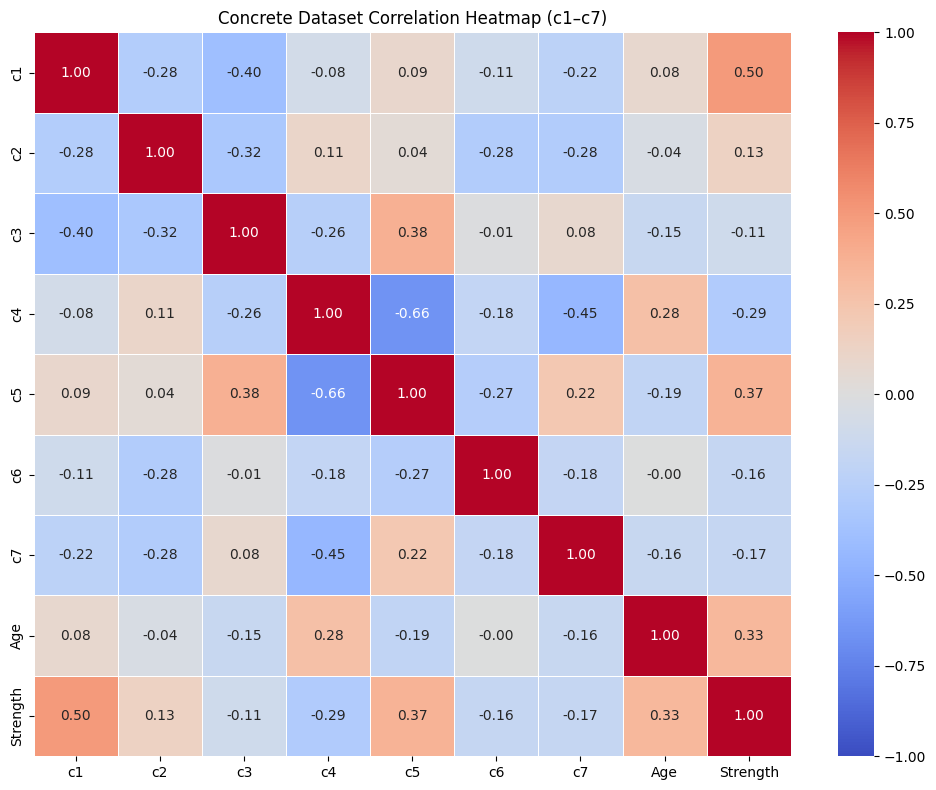

In [5]:
# 2. Rename the 7 components to c1-c7 (and shorten Age & Strength)
data.columns = ["c1", "c2", "c3", "c4", "c5", "c6", "c7", "Age", "Strength"]

# 3. Compute the correlation matrix
corr_matrix = data.corr()

# 4. Draw the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Concrete Dataset Correlation Heatmap (c1–c7)")
plt.tight_layout()
plt.show()


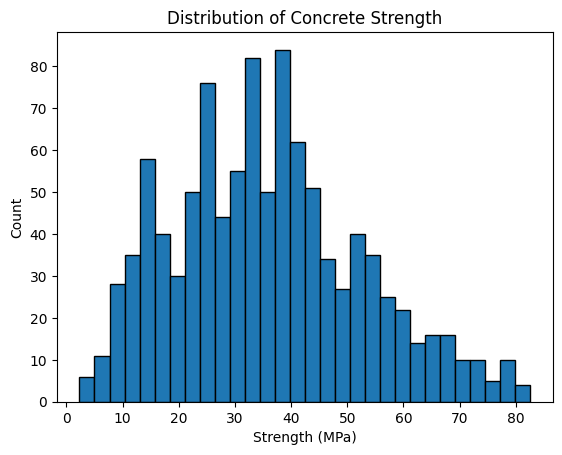

In [6]:
# Plot histogram for the target variable (Concrete Strength)
plt.hist(data.iloc[:, -1], bins=30, edgecolor='k')
plt.title('Distribution of Concrete Strength')
plt.xlabel('Strength (MPa)')
plt.ylabel('Count')
plt.show()

# Define inputs and target

In [7]:
# Inputs: all columns except the last one
inputs = data.iloc[:, :-1].values

# Targets: only the last column
targets = data.iloc[:, -1].values.reshape(-1, 1) 

print("Input shape:", inputs.shape)
print("Target shape:", targets.shape)

Input shape: (1030, 8)
Target shape: (1030, 1)


# Shuffle and split FIRST (on raw numpy data)

In [8]:
torch.manual_seed(42)
n_samples = inputs.shape[0]
indices = torch.randperm(n_samples).numpy()
split_idx = int(n_samples * 0.8)

train_indices = indices[:split_idx]
test_indices = indices[split_idx:]

X_train_raw, X_test_raw = inputs[train_indices], inputs[test_indices]
y_train_raw, y_test_raw = targets[train_indices], targets[test_indices]

# Fit scaler on TRAIN only, apply to both

In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Convert to PyTorch tensors

In [10]:
X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train_raw, dtype=torch.float32)
y_test = torch.tensor(y_test_raw, dtype=torch.float32)

# Initialize model parameters

In [11]:
num_features = X_train.shape[1]  # Should be 8
W = torch.randn((num_features, 1), requires_grad=True)
W.data *= 0.01  # Scale down initial values
b = torch.zeros((1,), requires_grad=True)

# 7. Confirm everything is set up
print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])
print("Weight shape:", W.shape)
print("Bias shape:", b.shape)

Training set size: 824
Test set size: 206
Weight shape: torch.Size([8, 1])
Bias shape: torch.Size([1])


# Forword Pass

In [12]:
def model(X):
    return X @ W + b

preds = model(X_train)
print(preds.shape)    
print(preds[:5])      

torch.Size([824, 1])
tensor([[-0.0063],
        [-0.0136],
        [ 0.0195],
        [-0.0190],
        [ 0.0048]], grad_fn=<SliceBackward0>)


### near 0, because W is tiny and b = 0

# Loss Function

In [13]:
def mse_loss(y_pred, y_true):
    return ((y_pred - y_true) ** 2).mean()

loss = mse_loss(model(X_train), y_train)
print("Initial loss:", loss.item())   

Initial loss: 1575.6337890625


# Gradients with autograd

In [14]:
loss=mse_loss(model(X_train),y_train)
loss.backward()
print("W.grad shape:", W.grad.shape)   # (8, 1)
print("b.grad shape:", b.grad.shape)   # (1,)
print("W.grad:", W.grad.flatten())
print("b.grad:", b.grad)

W.grad shape: torch.Size([8, 1])
b.grad shape: torch.Size([1])
W.grad: tensor([-16.8346,  -5.8524,   4.3915,  10.0784, -12.1290,   5.5485,   5.5982,
        -11.2073])
b.grad: tensor([-71.9041])


In [15]:
# Clear them, because we only did this to inspect
W.grad.zero_()
b.grad.zero_()

tensor([0.])

# Training loop (gradient descent)

In [16]:
# Re-initialize so training starts fresh
torch.manual_seed(42)
w = torch.randn((num_features),1)*0.01
w.requires_grad_(True)
b = torch.zeros((1,), requires_grad=True)

lr=0.01
epochs=1000
train_losses = []
test_losses = []

for epoch in range(epochs):
    # 1. Forward pass
    y_pred = model(X_train)
    loss = mse_loss(y_pred, y_train)

    # 2. Backward pass
    loss.backward()

    # 3. Update parameters (no gradient tracking here)
    with torch.no_grad():
        W -= lr * W.grad
        b -= lr * b.grad

    # 4. Zero the gradients for the next iteration
    W.grad.zero_()
    b.grad.zero_()

    # 5. Record the losses
    train_losses.append(loss.item())
    with torch.no_grad():
        test_losses.append(mse_loss(model(X_test), y_test).item())

    if epoch % 100 == 0:
        print(f"Epoch {epoch:4d} | Train MSE: {loss.item():8.3f} | Test MSE: {test_losses[-1]:8.3f}")

Epoch    0 | Train MSE: 1575.634 | Test MSE: 1448.159
Epoch  100 | Train MSE:  138.274 | Test MSE:  142.074
Epoch  200 | Train MSE:  110.690 | Test MSE:  122.709
Epoch  300 | Train MSE:  108.650 | Test MSE:  121.745
Epoch  400 | Train MSE:  107.731 | Test MSE:  121.090
Epoch  500 | Train MSE:  107.165 | Test MSE:  120.632
Epoch  600 | Train MSE:  106.784 | Test MSE:  120.301
Epoch  700 | Train MSE:  106.504 | Test MSE:  120.040
Epoch  800 | Train MSE:  106.285 | Test MSE:  119.817
Epoch  900 | Train MSE:  106.106 | Test MSE:  119.620


# Plot the loss curves

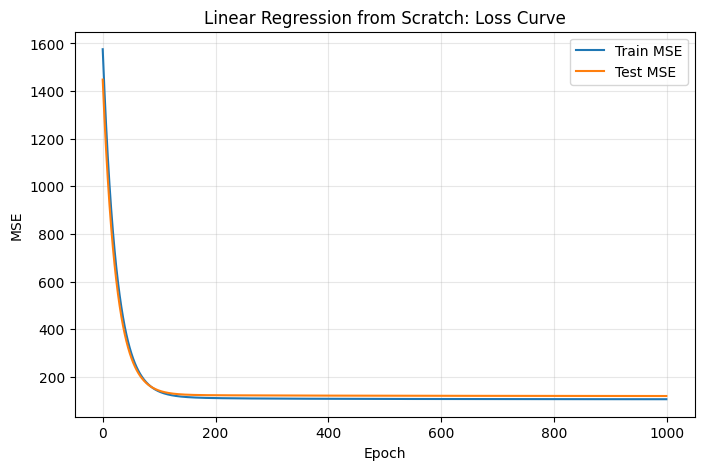

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train MSE")
plt.plot(test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Linear Regression from Scratch: Loss Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Evaluate (MSE, RMSE, R²)

In [18]:
def evaluate(X, y, name):
    with torch.no_grad():
        y_pred = model(X)
        mse = ((y_pred - y) ** 2).mean()
        rmse = torch.sqrt(mse)
        ss_res = ((y - y_pred) ** 2).sum()
        ss_tot = ((y - y.mean()) ** 2).sum()
        r2 = 1 - ss_res / ss_tot
    print(f"{name:5s} | MSE: {mse:7.2f} | RMSE: {rmse:5.2f} MPa | R²: {r2:.3f}")

evaluate(X_train, y_train, "Train")
evaluate(X_test,  y_test,  "Test")

Train | MSE:  105.95 | RMSE: 10.29 MPa | R²: 0.626
Test  | MSE:  119.44 | RMSE: 10.93 MPa | R²: 0.541


# Visual check, predicted vs. actual

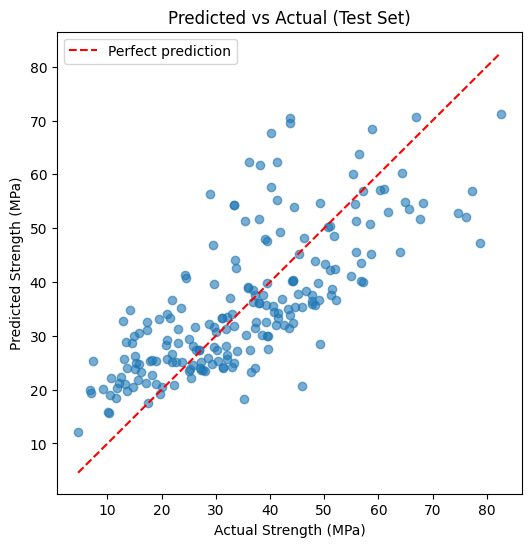

In [19]:
with torch.no_grad():
    y_pred_test = model(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test.numpy(), y_pred_test.numpy(), alpha=0.6)
lims = [y_test.min().item(), y_test.max().item()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Strength (MPa)")
plt.ylabel("Predicted Strength (MPa)")
plt.title("Predicted vs Actual (Test Set)")
plt.legend()
plt.show()

### Points hugging the red line mean good predictions. A curved or fanned-out cloud means the linear model is missing nonlinear structure, which is the motivation for the next step.